## Imports and global settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, average_precision_score)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 4)

RANDOM_STATE = 42
TEST_SIZE = 0.2          # hold-out fraction for both strategies
N_TOP_FEATURES = 30      # select top 30 features via mutual information

## Helper functions for temporal-aware splitting and evaluation

In [2]:
def temporal_split(X, y, time_vals, test_size=TEST_SIZE):
    """
    Chronological split: sort by time, test = last test_size fraction.
    """
    idx_sorted = np.argsort(time_vals)
    X_sorted = X.iloc[idx_sorted].reset_index(drop=True)
    y_sorted = y.iloc[idx_sorted].reset_index(drop=True)
    n_test = int(len(X_sorted) * test_size)
    X_train, X_test = X_sorted[:-n_test], X_sorted[-n_test:]
    y_train, y_test = y_sorted[:-n_test], y_sorted[-n_test:]
    return X_train, X_test, y_train, y_test

def random_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE):
    """
    Standard random train/test split (no time order).
    """
    return train_test_split(X, y, test_size=test_size,
                            random_state=random_state, shuffle=True)

def run_experiment(X, y, time_vals, split_func, split_kwargs, top_k=N_TOP_FEATURES):
    """
    Complete pipeline with zero leakage:
      1. Split data
      2. Impute missing values (fit on train)
      3. Select top_k features via mutual information (on train)
      4. Scale (fit on train)
      5. Train seven diverse classifiers, evaluate on test
    Returns: dict of model->metric dict.
    """
    # ----- 1. Split -----
    X_train, X_test, y_train, y_test = split_func(X, y, **split_kwargs)

    # ----- 2. Imputation -----
    numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
    X_train_num = X_train[numeric_cols].copy()
    X_test_num  = X_test[numeric_cols].copy()

    valid_cols = [c for c in numeric_cols if X_train_num[c].notna().any()]
    X_train_num = X_train_num[valid_cols]
    X_test_num  = X_test_num[valid_cols]

    imputer = SimpleImputer(strategy='median')
    X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_num),
                               columns=valid_cols)
    X_test_imp  = pd.DataFrame(imputer.transform(X_test_num),
                               columns=valid_cols)

    # ----- 3. Feature selection (Mutual Information, train only) -----
    mi_scores = mutual_info_classif(X_train_imp, y_train, random_state=RANDOM_STATE)
    mi_df = pd.DataFrame({'feature': valid_cols, 'mi': mi_scores})
    mi_df = mi_df.sort_values('mi', ascending=False)
    selected_features = mi_df.head(top_k)['feature'].tolist()
    print(f"   Selected {len(selected_features)} features (top 5): {selected_features[:5]} ...")

    X_train_sel = X_train_imp[selected_features]
    X_test_sel  = X_test_imp[selected_features]

    # ----- 4. Scaling -----
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train_sel)
    X_test_s  = scaler.transform(X_test_sel)

    # ----- 5. Modelling: 7 diverse classifiers -----
    models = {
        # Linear
        'Logistic Regression': LogisticRegression(
            max_iter=2000, random_state=RANDOM_STATE,
            class_weight='balanced'
        ),
        # Distance-based
        'k‑Nearest Neighbors': KNeighborsClassifier(
            n_neighbors=5, n_jobs=-1
        ),
        # Bagging ensemble
        'Random Forest': RandomForestClassifier(
            n_estimators=100, random_state=RANDOM_STATE,
            n_jobs=-1, class_weight='balanced'
        ),
        # Boosting ensembles
        'XGBoost': XGBClassifier(
            n_estimators=100, random_state=RANDOM_STATE,
            use_label_encoder=False, eval_metric='logloss',
            verbosity=0, scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
        ),
        'LightGBM': LGBMClassifier(
            n_estimators=100, random_state=RANDOM_STATE,
            class_weight='balanced', verbose=-1
        ),
        'Gradient Boosting': GradientBoostingClassifier(
            n_estimators=100, random_state=RANDOM_STATE
        ),
        # Neural network
        'MLP (Neural Net)': MLPClassifier(
            hidden_layer_sizes=(64, 32), max_iter=500,
            random_state=RANDOM_STATE, early_stopping=True
        ),
    }

    results = {}
    for name, model in models.items():
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)
        y_proba = model.predict_proba(X_test_s)[:, 1]

        results[name] = {
            'AUROC': roc_auc_score(y_test, y_proba),
            'F1': f1_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred),
            'AUC-PR': average_precision_score(y_test, y_proba)
        }
    return results

def print_results(res, title):
    print(f"\n{title}")
    for model, m in res.items():
        print(f"  {model}: AUROC={m['AUROC']:.4f}, F1={m['F1']:.4f}, "
              f"Precision={m['Precision']:.4f}, Recall={m['Recall']:.4f}, AUC-PR={m['AUC-PR']:.4f}")

# Dataset 1 – IEEE-CIS Fraud Detection

In [3]:
# Load training transaction data (has labels)
train_id = pd.read_csv("../../Dataset/ieee-fraud-detection/train_transaction.csv")

# Target and time column
target = 'isFraud'
time_col = 'TransactionDT'

# we don't need it ID column
df_raw = train_id.drop(columns=['TransactionID'])

print(f"Full dataset shape: {df_raw.shape}")
print(f"Fraud rate: {df_raw[target].mean():.4%}")

Full dataset shape: (590540, 393)
Fraud rate: 3.4990%


## Prepare raw feature matrix and target vector (no preprocessing!)

In [4]:
# We keep only numeric columns + target + time for splitting.
# The function run_experiment will handle further filtering inside.
X_all = df_raw.drop(columns=[target, time_col])  # raw features
y_all = df_raw[target]
time_all = df_raw[time_col].values

# Remove any columns that are not numeric (to make our work easier)
X_all = X_all.select_dtypes(include=[np.number])
print(f"Raw numeric feature count: {X_all.shape[1]}")

Raw numeric feature count: 377


## Run temporal split experiment (chronological)

In [5]:
print("=== TEMPORAL SPLIT (chronological) ===")
res_temp = run_experiment(X_all, y_all, time_all,
                          temporal_split, {'time_vals': time_all})

# Run random split experiment
print("\n=== RANDOM SPLIT (time-ignorant) ===")
res_rand = run_experiment(X_all, y_all, time_all,
                          random_split, {})

=== TEMPORAL SPLIT (chronological) ===
   Selected 30 features (top 5): ['addr2', 'V251', 'V247', 'V250', 'V245'] ...

=== RANDOM SPLIT (time-ignorant) ===
   Selected 30 features (top 5): ['V246', 'V258', 'V198', 'V149', 'V155'] ...


## Display and compare results

In [6]:
print_results(res_temp, "TEMPORAL SPLIT")
print_results(res_rand, "RANDOM SPLIT")

# Compute inflation (in %)
print("\n--- METRIC INFLATION (Random over Temporal) ---")
for metric in ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']:
    for model in res_temp:
        temp_val = res_temp[model][metric]
        rand_val = res_rand[model][metric]
        infl = 100 * (rand_val - temp_val) / temp_val
        print(f"{model:20s} | {metric:10s}: +{infl:6.1f}%")


TEMPORAL SPLIT
  Logistic Regression: AUROC=0.6933, F1=0.1912, Precision=0.1187, Recall=0.4911, AUC-PR=0.2822
  k‑Nearest Neighbors: AUROC=0.6464, F1=0.2947, Precision=0.6565, Recall=0.1900, AUC-PR=0.2195
  Random Forest: AUROC=0.6569, F1=0.1922, Precision=0.1248, Recall=0.4188, AUC-PR=0.2167
  XGBoost: AUROC=0.6886, F1=0.2274, Precision=0.1544, Recall=0.4313, AUC-PR=0.3027
  LightGBM: AUROC=0.6945, F1=0.2320, Precision=0.1579, Recall=0.4373, AUC-PR=0.3060
  Gradient Boosting: AUROC=0.7039, F1=0.3044, Precision=0.7776, Recall=0.1892, AUC-PR=0.3009
  MLP (Neural Net): AUROC=0.6956, F1=0.3071, Precision=0.7411, Recall=0.1937, AUC-PR=0.2984

RANDOM SPLIT
  Logistic Regression: AUROC=0.7078, F1=0.2147, Precision=0.1408, Recall=0.4519, AUC-PR=0.2862
  k‑Nearest Neighbors: AUROC=0.6768, F1=0.3640, Precision=0.7630, Recall=0.2390, AUC-PR=0.2909
  Random Forest: AUROC=0.6895, F1=0.2332, Precision=0.1620, Recall=0.4165, AUC-PR=0.2720
  XGBoost: AUROC=0.7261, F1=0.2310, Precision=0.1506, Recall

## bar chart comparison

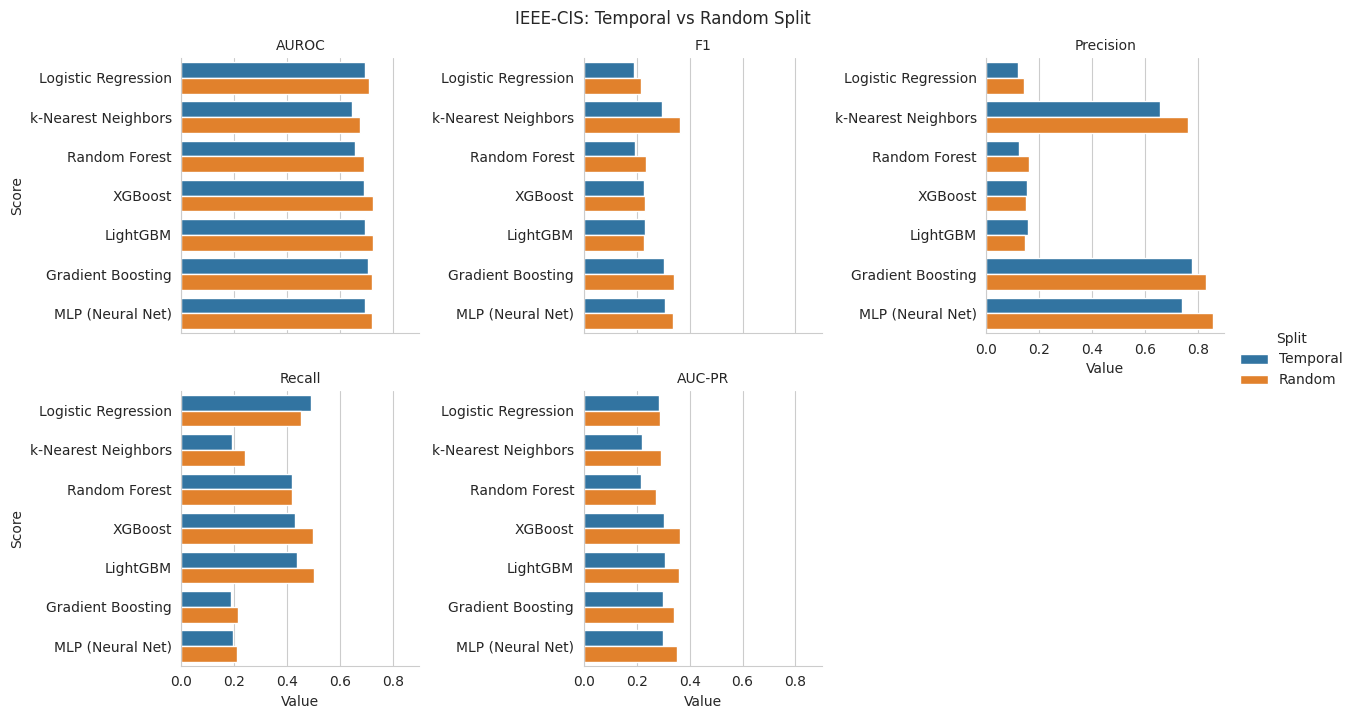

In [7]:
df_comp = []
for model in res_temp:
    for metric in ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']:
        df_comp.append({'Model': model, 'Metric': metric,
                        'Temporal': res_temp[model][metric],
                        'Random': res_rand[model][metric]})
df_comp = pd.DataFrame(df_comp)

# Melt for seaborn
df_plot = df_comp.melt(id_vars=['Model', 'Metric'],
                       value_vars=['Temporal', 'Random'],
                       var_name='Split', value_name='Value')

g = sns.catplot(data=df_plot, x='Value', y='Model', hue='Split',
                col='Metric', kind='bar', col_wrap=3,
                height=3.5, aspect=1.2, sharey=False)
g.set_titles("{col_name}")
g.set_ylabels("Score")
plt.suptitle("IEEE‑CIS: Temporal vs Random Split ", y=1.02)
plt.show()

# Dataset 2 – Sparkov synthetic fraud data (temporal)

In [8]:
# Load and combine train + test
sparkov_train = pd.read_csv("../../Dataset/SparkovGeneratedData/fraudTrain.csv")
sparkov_test  = pd.read_csv("../../Dataset/SparkovGeneratedData/fraudTest.csv")
df_sparkov_raw = pd.concat([sparkov_train, sparkov_test], ignore_index=True)

target_sp = 'is_fraud'
time_col_sp = 'trans_date_trans_time'

# Convert timestamp to ordinal for sorting
df_sparkov_raw[time_col_sp] = pd.to_datetime(df_sparkov_raw[time_col_sp])
df_sparkov_raw['time_ordinal'] = df_sparkov_raw[time_col_sp].map(pd.Timestamp.toordinal)

print(f"\nSparkov full dataset shape: {df_sparkov_raw.shape}")
print(f"Sparkov fraud rate: {df_sparkov_raw[target_sp].mean():.4%}")

# Drop non-numeric columns that cannot be used
non_numeric_cols = df_sparkov_raw.select_dtypes(exclude=[np.number]).columns.tolist()
drop_cols = [target_sp, time_col_sp, 'time_ordinal'] + non_numeric_cols
print(f"Dropping non-numeric columns: {non_numeric_cols}")

X_sp_all = df_sparkov_raw.drop(columns=drop_cols)
y_sp_all = df_sparkov_raw[target_sp]
time_sp_all = df_sparkov_raw['time_ordinal'].values

print(f"Sparkov numeric feature count: {X_sp_all.shape[1]}")


Sparkov full dataset shape: (1852394, 24)
Sparkov fraud rate: 0.5210%
Dropping non-numeric columns: ['trans_date_trans_time', 'merchant', 'category', 'first', 'last', 'gender', 'street', 'city', 'state', 'job', 'dob', 'trans_num']
Sparkov numeric feature count: 10


## Run temporal vs random split on Sparkov dataset

In [9]:
print("\n=== SPARKOV – TEMPORAL SPLIT (chronological) ===")
res_temp_sp = run_experiment(X_sp_all, y_sp_all, time_sp_all,
                             temporal_split, {'time_vals': time_sp_all})

print("\n=== SPARKOV – RANDOM SPLIT (time-ignorant) ===")
res_rand_sp = run_experiment(X_sp_all, y_sp_all, time_sp_all,
                             random_split, {})

print_results(res_temp_sp, "SPARKOV TEMPORAL SPLIT")
print_results(res_rand_sp, "SPARKOV RANDOM SPLIT")

print("\n--- SPARKOV METRIC INFLATION (Random over Temporal) ---")
for metric in ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']:
    for model in res_temp_sp:
        temp_val = res_temp_sp[model][metric]
        rand_val = res_rand_sp[model][metric]
        if temp_val == 0:
            if rand_val == 0:
                print(f"{model:20s} | {metric:10s}:   0 → 0  (no change)")
            else:
                print(f"{model:20s} | {metric:10s}:   0 → {rand_val:.4f}  (infinite inflation, model collapsed under temporal split)")
        else:
            infl = 100 * (rand_val - temp_val) / temp_val
            print(f"{model:20s} | {metric:10s}: +{infl:6.1f}%")


=== SPARKOV – TEMPORAL SPLIT (chronological) ===
   Selected 10 features (top 5): ['amt', 'unix_time', 'Unnamed: 0', 'lat', 'zip'] ...

=== SPARKOV – RANDOM SPLIT (time-ignorant) ===
   Selected 10 features (top 5): ['amt', 'unix_time', 'Unnamed: 0', 'long', 'lat'] ...

SPARKOV TEMPORAL SPLIT
  Logistic Regression: AUROC=0.8390, F1=0.1500, Precision=0.0832, Recall=0.7598, AUC-PR=0.1386
  k‑Nearest Neighbors: AUROC=0.7401, F1=0.2871, Precision=0.3474, Recall=0.2446, AUC-PR=0.1503
  Random Forest: AUROC=0.8586, F1=0.0388, Precision=0.6429, Recall=0.0200, AUC-PR=0.1852
  XGBoost: AUROC=0.8035, F1=0.1185, Precision=0.0723, Recall=0.3284, AUC-PR=0.0702
  LightGBM: AUROC=0.9498, F1=0.1147, Precision=0.0622, Recall=0.7391, AUC-PR=0.1643
  Gradient Boosting: AUROC=0.9431, F1=0.4050, Precision=0.3810, Recall=0.4322, AUC-PR=0.2636
  MLP (Neural Net): AUROC=0.9364, F1=0.2455, Precision=0.5255, Recall=0.1601, AUC-PR=0.3165

SPARKOV RANDOM SPLIT
  Logistic Regression: AUROC=0.8389, F1=0.1422, Prec

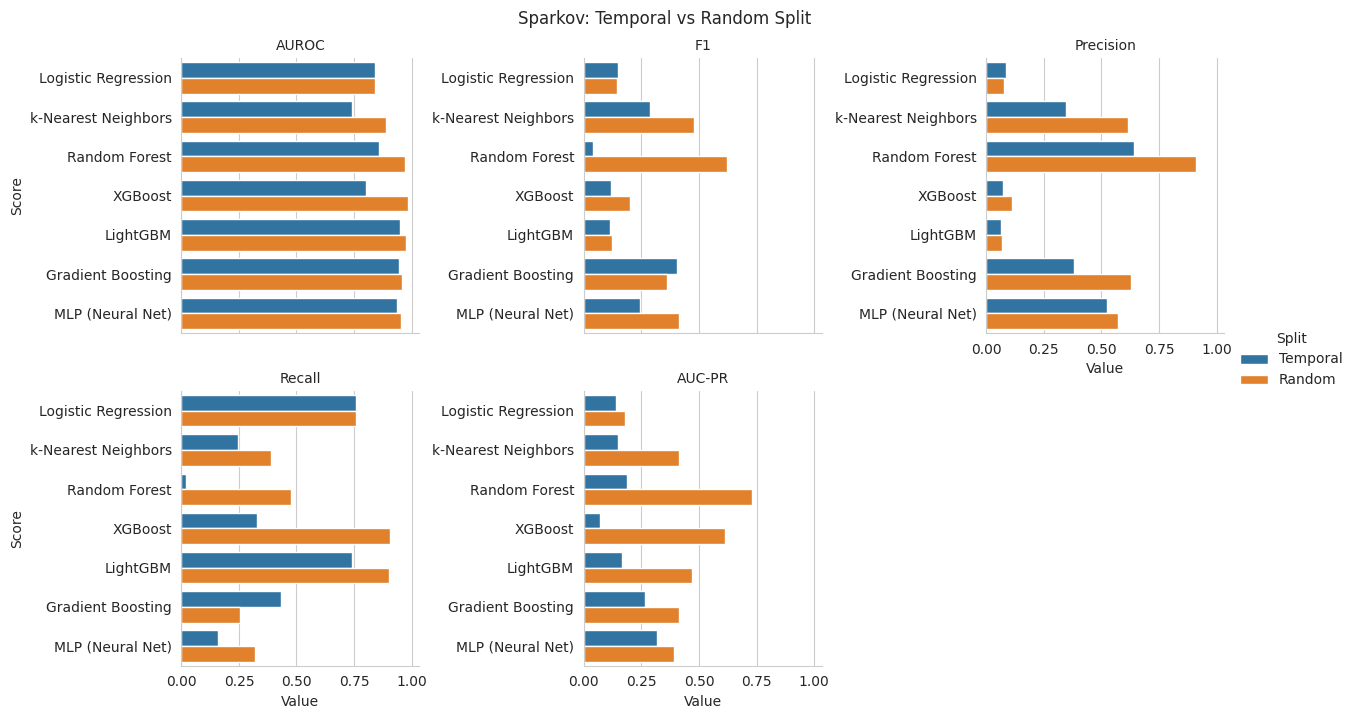

In [10]:
df_comp_2 = []
for model in res_temp_sp:
    for metric in ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']:
        df_comp_2.append({'Model': model, 'Metric': metric,
                        'Temporal': res_temp_sp[model][metric],
                        'Random': res_rand_sp[model][metric]})
df_comp_2 = pd.DataFrame(df_comp_2)

# Melt for seaborn
df_plot = df_comp_2.melt(id_vars=['Model', 'Metric'],
                       value_vars=['Temporal', 'Random'],
                       var_name='Split', value_name='Value')

g = sns.catplot(data=df_plot, x='Value', y='Model', hue='Split',
                col='Metric', kind='bar', col_wrap=3,
                height=3.5, aspect=1.2, sharey=False)
g.set_titles("{col_name}")
g.set_ylabels("Score")
plt.suptitle("Sparkov: Temporal vs Random Split", y=1.02)
plt.show()

## Aggregate all results into a single DataFrame for comparison

In [11]:
def results_to_df(res_temp, res_rand, dataset_name):
    rows = []
    for model in res_temp:
        rows.append({
            'Dataset': dataset_name, 'Model': model, 'Split': 'Temporal',
            'AUROC': res_temp[model]['AUROC'], 'F1': res_temp[model]['F1'],
            'Precision': res_temp[model]['Precision'],
            'Recall': res_temp[model]['Recall'],
            'AUC-PR': res_temp[model]['AUC-PR']
        })
        rows.append({
            'Dataset': dataset_name, 'Model': model, 'Split': 'Random',
            'AUROC': res_rand[model]['AUROC'], 'F1': res_rand[model]['F1'],
            'Precision': res_rand[model]['Precision'],
            'Recall': res_rand[model]['Recall'],
            'AUC-PR': res_rand[model]['AUC-PR']
        })
    return pd.DataFrame(rows)

df_ieee = results_to_df(res_temp, res_rand, 'IEEE-CIS')
df_sp   = results_to_df(res_temp_sp, res_rand_sp, 'Sparkov')
all_res = pd.concat([df_ieee, df_sp], ignore_index=True)

# Compute inflation table per (Dataset, Model, Metric)
# Use np.inf where temporal = 0 and random > 0
metrics_list = ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']
for metric in metrics_list:
    pivot = all_res.pivot_table(index=['Dataset', 'Model'],
                                columns='Split', values=metric)
    # Avoid division by zero: compute inflation manually
    infl_values = []
    for idx, row in pivot.iterrows():
        temp_v = row['Temporal']
        rand_v = row['Random']
        if temp_v == 0:
            infl_values.append(np.inf if rand_v > 0 else 0.0)
        else:
            infl_values.append(100 * (rand_v - temp_v) / temp_v)
    pivot['Inflation %'] = infl_values
    print(f"\n=== {metric} Inflation (Random vs Temporal) ===")
    # Replace inf with a string for display
    display_pivot = pivot.copy()
    display_pivot['Inflation %'] = display_pivot['Inflation %'].apply(
        lambda x: '∞' if np.isinf(x) else f"{x:.1f}"
    )
    print(display_pivot[['Temporal', 'Random', 'Inflation %']])


=== AUROC Inflation (Random vs Temporal) ===
Split                         Temporal    Random Inflation %
Dataset  Model                                              
IEEE-CIS Gradient Boosting    0.703884  0.720530         2.4
         LightGBM             0.694530  0.726193         4.6
         Logistic Regression  0.693304  0.707756         2.1
         MLP (Neural Net)     0.695609  0.721108         3.7
         Random Forest        0.656877  0.689496         5.0
         XGBoost              0.688584  0.726092         5.4
         k‑Nearest Neighbors  0.646416  0.676780         4.7
Sparkov  Gradient Boosting    0.943147  0.958077         1.6
         LightGBM             0.949803  0.976182         2.8
         Logistic Regression  0.839048  0.838902        -0.0
         MLP (Neural Net)     0.936440  0.952595         1.7
         Random Forest        0.858635  0.971280        13.1
         XGBoost              0.803454  0.985026        22.6
         k‑Nearest Neighbors  0.740057 

## Overall average inflation (across datasets) per metric and model

In [12]:
print("\n=== OVERALL AVERAGE INFLATION (across 2 datasets) ===")
MODEL_NAMES = [
    'Logistic Regression',
    'k‑Nearest Neighbors',
    'Random Forest',
    'XGBoost',
    'LightGBM',
    'Gradient Boosting',
    'MLP (Neural Net)',
]
summary_rows = []
for model in MODEL_NAMES:
    for metric in metrics_list:
        infls = []
        inf_count = 0
        for dataset in ['IEEE-CIS', 'Sparkov']:
            temp_v = all_res[(all_res['Dataset'] == dataset) & 
                             (all_res['Model'] == model) & 
                             (all_res['Split'] == 'Temporal')][metric].values[0]
            rand_v = all_res[(all_res['Dataset'] == dataset) & 
                             (all_res['Model'] == model) & 
                             (all_res['Split'] == 'Random')][metric].values[0]
            if temp_v == 0:
                if rand_v > 0:
                    inf_count += 1
            else:
                infls.append(100 * (rand_v - temp_v) / temp_v)
        avg_infl = np.mean(infls) if infls else np.nan
        summary_rows.append({
            'Model': model, 'Metric': metric,
            'Avg Inflation %': avg_infl,
            'Datasets with ∞': inf_count
        })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.pivot_table(index='Model', columns='Metric', 
                              values='Avg Inflation %').round(1))


=== OVERALL AVERAGE INFLATION (across 2 datasets) ===
Metric               AUC-PR  AUROC     F1  Precision  Recall
Model                                                       
Gradient Boosting      34.8    2.0    0.6       36.0   -14.1
LightGBM              101.0    3.7    2.6       -0.4    18.3
Logistic Regression    15.7    1.0    3.5        6.4    -4.1
MLP (Neural Net)       20.8    2.7   38.7       12.3    54.4
Random Forest         160.2    9.0  763.3       35.6  1134.2
XGBoost               397.7   14.0   35.9       27.2    95.3
k‑Nearest Neighbors   104.4   12.3   44.9       46.5    42.8


## Bar chart – all datasets side by side

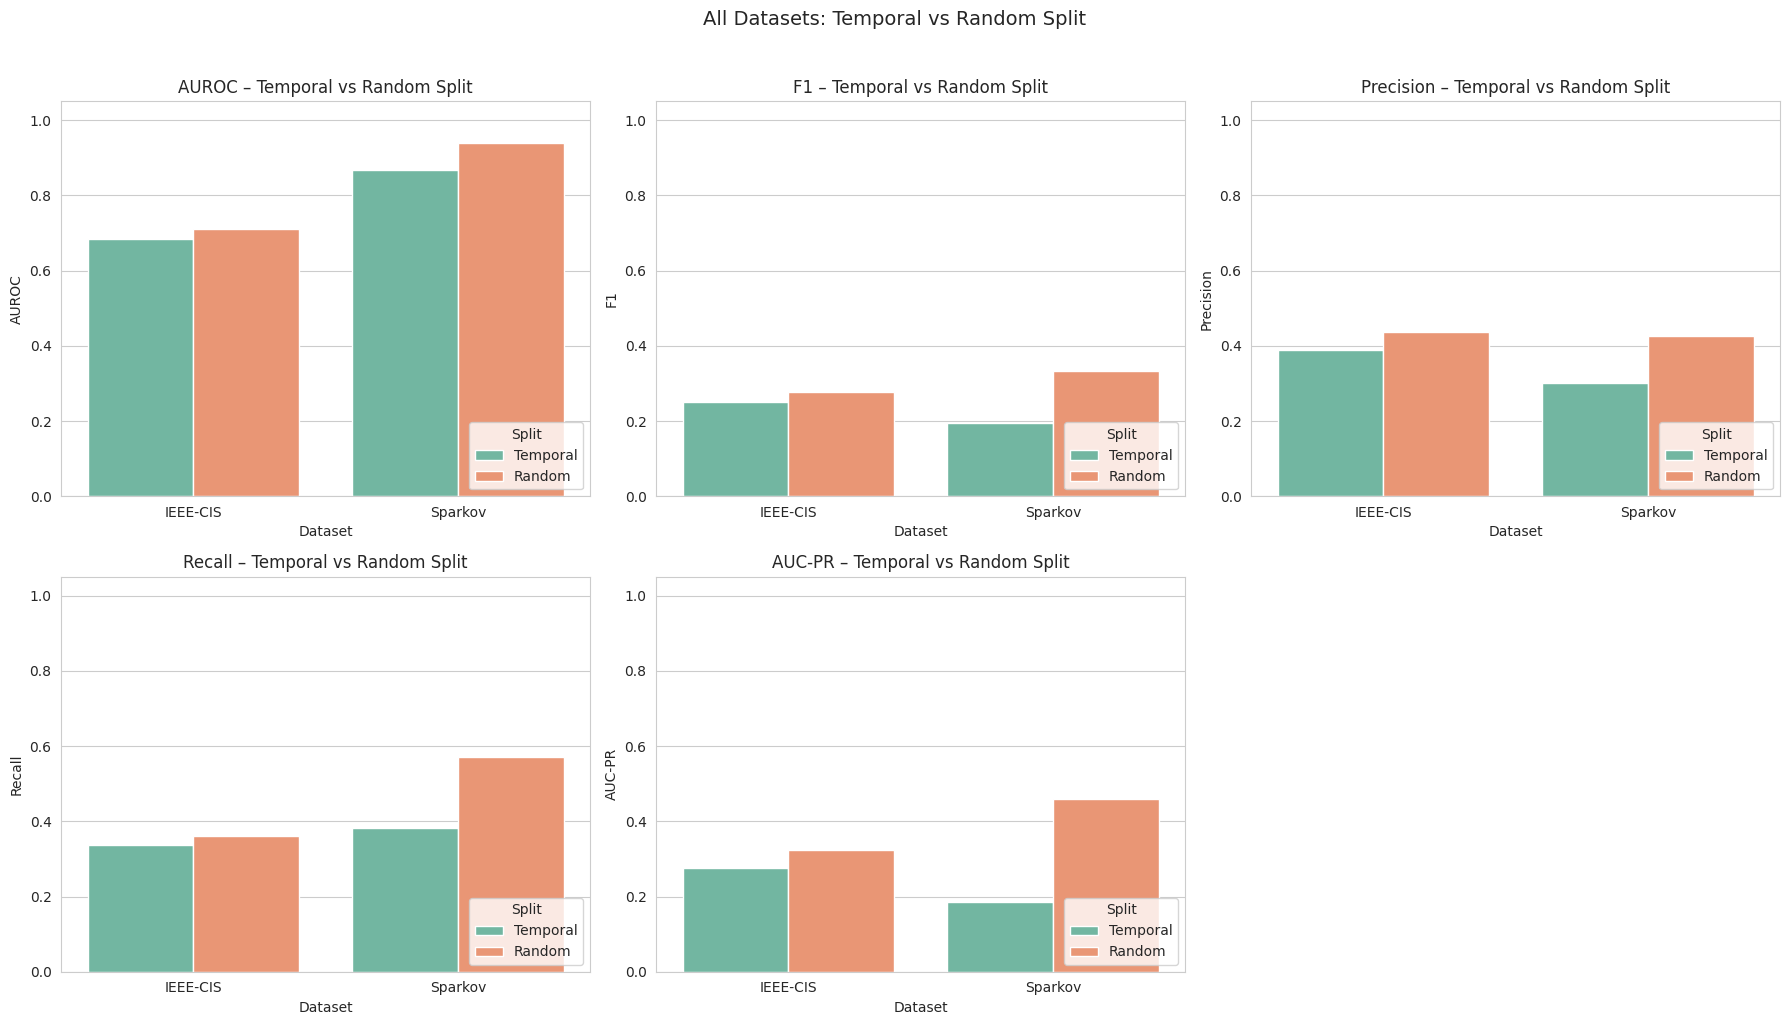

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics_list):
    ax = axes[i]
    sns.barplot(data=all_res, x='Dataset', y=metric, hue='Split', ax=ax,
                palette='Set2', errorbar=None)
    ax.set_title(f'{metric} – Temporal vs Random Split')
    ax.set_ylim(0, 1.05)
    ax.legend(title='Split', loc='lower right')
# Hide last empty subplot
axes[-1].axis('off')
plt.suptitle("All Datasets: Temporal vs Random Split", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## Compact LaTeX‑style summary table

In [14]:
# The model name list must match exactly what is in the models dict
# --- Overall average inflation ---
print("\n=== OVERALL AVERAGE INFLATION (across 2 datasets) ===")

summary_rows = []
for model in MODEL_NAMES:
    for metric in metrics_list:
        infls = []
        inf_count = 0
        for dataset in ['IEEE-CIS', 'Sparkov']:
            temp_v = all_res[(all_res['Dataset'] == dataset) & 
                             (all_res['Model'] == model) & 
                             (all_res['Split'] == 'Temporal')][metric].values[0]
            rand_v = all_res[(all_res['Dataset'] == dataset) & 
                             (all_res['Model'] == model) & 
                             (all_res['Split'] == 'Random')][metric].values[0]
            if temp_v == 0:
                if rand_v > 0:
                    inf_count += 1
            else:
                infls.append(100 * (rand_v - temp_v) / temp_v)
        avg_infl = np.mean(infls) if infls else np.nan
        summary_rows.append({
            'Model': model, 'Metric': metric,
            'Avg Inflation %': avg_infl,
            'Datasets with ∞': inf_count
        })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.pivot_table(index='Model', columns='Metric', 
                              values='Avg Inflation %').round(1))

# --- LaTeX‑friendly F1 inflation ---
print("\n--- LaTeX‑friendly summary: F1 Inflation ---")
for dataset in ['IEEE-CIS', 'Sparkov']:
    sub = all_res[(all_res['Dataset'] == dataset)]
    for model in MODEL_NAMES:
        temp_f1 = sub[(sub['Model'] == model) & (sub['Split'] == 'Temporal')]['F1'].values[0]
        rand_f1 = sub[(sub['Model'] == model) & (sub['Split'] == 'Random')]['F1'].values[0]
        if temp_f1 == 0:
            infl_str = "∞" if rand_f1 > 0 else "0"
        else:
            infl_str = f"{100*(rand_f1-temp_f1)/temp_f1:+.1f}\\%"
        print(f"  {dataset:15s} & {model:22s} & {temp_f1:.3f} & {rand_f1:.3f} & {infl_str} \\\\")

# --- Average F1 inflation ---
print("\n--- Average F1 Inflation (IEEE + Sparkov) ---")
for model in MODEL_NAMES:
    infls = []
    for dataset in ['IEEE-CIS', 'Sparkov']:
        sub = all_res[(all_res['Dataset'] == dataset)]
        temp_f1 = sub[(sub['Model'] == model) & (sub['Split'] == 'Temporal')]['F1'].values[0]
        rand_f1 = sub[(sub['Model'] == model) & (sub['Split'] == 'Random')]['F1'].values[0]
        if temp_f1 > 0:
            infls.append(100 * (rand_f1 - temp_f1) / temp_f1)
    if infls:
        print(f"  {model:22s}: avg F1 inflation = {np.mean(infls):+.1f}%")
    else:
        print(f"  {model:22s}: all temporal F1 = 0 (infinite inflation)")


=== OVERALL AVERAGE INFLATION (across 2 datasets) ===
Metric               AUC-PR  AUROC     F1  Precision  Recall
Model                                                       
Gradient Boosting      34.8    2.0    0.6       36.0   -14.1
LightGBM              101.0    3.7    2.6       -0.4    18.3
Logistic Regression    15.7    1.0    3.5        6.4    -4.1
MLP (Neural Net)       20.8    2.7   38.7       12.3    54.4
Random Forest         160.2    9.0  763.3       35.6  1134.2
XGBoost               397.7   14.0   35.9       27.2    95.3
k‑Nearest Neighbors   104.4   12.3   44.9       46.5    42.8

--- LaTeX‑friendly summary: F1 Inflation ---
  IEEE-CIS        & Logistic Regression    & 0.191 & 0.215 & +12.3\% \\
  IEEE-CIS        & k‑Nearest Neighbors    & 0.295 & 0.364 & +23.5\% \\
  IEEE-CIS        & Random Forest          & 0.192 & 0.233 & +21.3\% \\
  IEEE-CIS        & XGBoost                & 0.227 & 0.231 & +1.6\% \\
  IEEE-CIS        & LightGBM               & 0.232 & 0.228 & -1